# 02 Ridge Regression Baseline

## 1. Experiment Objective

Estimate `motor_UPDRS` from 16 voice features using Ridge regression.
Evaluate the model on patients whose recordings were not used in training.
Report mean absolute error (MAE) in UPDRS points.

## 2. How Ridge Regression Learns

Ridge predicts `motor_UPDRS` using an intercept and a weighted sum of the
16 voice features. During training, it selects weights that minimize the
sum of squared prediction errors plus a penalty on the squared weights.

The parameter `alpha` controls the strength of this penalty. A larger
`alpha` shrinks weights more strongly toward zero. If the penalty is too
strong, the model may underfit.

## 3. Import Libraries

In [8]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 4. Prepare the Inputs, Target, and Patient Groups

Use voice measurements to predict the motor UPDRS score. Keep patient
identifiers separate so that recordings can later be split by patient.

In [2]:
data_path = Path("../data/parkinsons_updrs.data")
df = pd.read_csv(data_path)

non_voice_columns = [
    "subject#", "age", "sex", "test_time", "motor_UPDRS", "total_UPDRS"
]

X = df.drop(columns=non_voice_columns)
y = df["motor_UPDRS"]
groups = df["subject#"]

print("Input shape (recordings, features):", X.shape)
print("Target:", y.name)
print("Unique patients:", groups.nunique())

Input shape (recordings, features): (5875, 16)
Target: motor_UPDRS
Unique patients: 42


### Observation

The input matrix contains 5,875 recordings and 16 voice features.
The prediction target is `motor_UPDRS`. The 42 patient identifiers are
kept separate from the model inputs for the patient-wise split.

## 5. Split the Data by Patient

Hold out approximately 20% of patients for testing. Verify that no
patient contributes recordings to both the training and test sets.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])
shared_patients = train_patients & test_patients

print("Training patients:", len(train_patients))
print("Test patients:", len(test_patients))
print("Patients in both sets:", len(shared_patients))

Training patients: 33
Test patients: 9
Patients in both sets: 0


### Observation

The split assigns 33 patients to training and 9 to testing, with no
patient overlap. The test set therefore evaluates predictions for
patients whose recordings were not used during training.

## 6. Train the Ridge Baseline

Fit a standardization and Ridge regression pipeline on the training
patients. Use α = 1.0 as the initial baseline setting.

In [4]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0)),
])

ridge_pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('ridge', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None


## 7. Predict Motor UPDRS Scores for Held-Out Patients

Use the fitted pipeline to predict a motor UPDRS score for each test
recording. Preview the predictions alongside their reference scores.

In [5]:
y_pred = ridge_pipeline.predict(X_test)

prediction_preview = pd.DataFrame({
    "patient_id": groups.iloc[test_idx].to_numpy(),
    "reference_motor_UPDRS": y_test.to_numpy(),
    "predicted_motor_UPDRS": y_pred,
})

prediction_preview.head(5).round(2)

,patient_id,reference_motor_UPDRS,predicted_motor_UPDRS
0,5,31.0,20.00
1,5,31.0,24.43
2,5,31.0,22.03
3,5,31.0,20.79
4,5,31.0,20.83


In [9]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

MAE: 7.0605
RMSE: 8.7180
R² Score: -0.3035


### Observation

Across recordings from nine held-out patients, Ridge produced an MAE
of 7.06 motor UPDRS points and an RMSE of 8.72 points. The negative
R² (−0.3035) indicates that Ridge had greater squared error than the
test-mean reference on this split.

## 9. Save the Ridge Baseline Results

Save the test metrics and patient split details for comparison with later models.

In [10]:
ridge_results = pd.DataFrame([{
    "model": "Ridge",
    "alpha": ridge_pipeline.named_steps["ridge"].alpha,
    "target": y_test.name,
    "split_seed": splitter.random_state,
    "train_patients": len(train_patients),
    "test_patients": len(test_patients),
    "test_recordings": len(y_test),
    "mae": 7.0605,
    "rmse": 8.7180,
    "r2": -0.3035,
}])

results_path = Path("../results/ridge_baseline_metrics.csv")
results_path.parent.mkdir(exist_ok=True)
ridge_results.to_csv(results_path, index=False)

print(f"Saved: {results_path}")

Saved: ..\results\ridge_baseline_metrics.csv


## 10. Compare Reference and Predicted Motor Scores

Plot each test recording against its reference score. The diagonal line
represents an exact prediction.

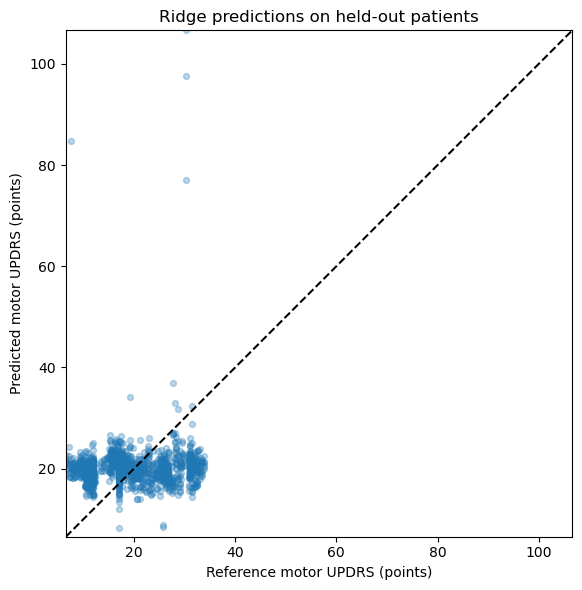

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, alpha=0.3, s=18)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
ax.plot([low, high], [low, high], "--", color="black")

ax.set(
    title="Ridge predictions on held-out patients",
    xlabel="Reference motor UPDRS (points)",
    ylabel="Predicted motor UPDRS (points)",
    xlim=(low, high),
    ylim=(low, high),
)
ax.set_aspect("equal")
fig.tight_layout()

plot_path = Path("../plots/ridge_reference_vs_predicted.png")
plot_path.parent.mkdir(exist_ok=True)
fig.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

### Observation

Most Ridge predictions cluster near 20 motor UPDRS points. On this test
split, the model tends to overestimate lower reference scores and
underestimate higher ones. A few recordings have unusually large
overpredictions, including one above 100 for a reference score near 30.

### 11. Inspect the five largest prediction errors

In [12]:
errors = prediction_preview.copy()
errors["dataset_row"] = X_test.index
errors["error"] = errors["predicted_motor_UPDRS"] - errors["reference_motor_UPDRS"]
errors["absolute_error"] = errors["error"].abs()

columns = ["dataset_row", "patient_id", "reference_motor_UPDRS",
           "predicted_motor_UPDRS", "error", "absolute_error"]

errors.nlargest(5, "absolute_error")[columns].round(2)

,dataset_row,patient_id,reference_motor_UPDRS,predicted_motor_UPDRS,error,absolute_error
333,1880,14,7.65,84.72,77.07,77.07
861,4063,30,30.28,106.62,76.33,76.33
904,4106,30,30.28,97.55,67.26,67.26
841,4043,30,30.28,76.98,46.70,46.70
400,1947,14,7.10,24.34,17.23,17.23


**Observation:** All five recordings with the largest absolute errors were overpredicted. Three belonged to patient 30 and two to patient 14. The largest error was 77.07 points: Ridge predicted 84.72 for a recording with a reference motor UPDRS score of 7.65.

### 12. Calculate the training mean for the baseline

In [13]:
baseline_score = y_train.mean()
print(f"Training mean motor UPDRS: {baseline_score:.4f}")

Training mean motor UPDRS: 21.6464


In [14]:
baseline_pred = pd.Series(baseline_score, index=y_test.index, name="baseline_prediction")

pd.DataFrame({
    "reference_motor_UPDRS": y_test,
    "baseline_prediction": baseline_pred
}).head().round(4)

,reference_motor_UPDRS,baseline_prediction
575,31.0,21.6464
576,31.0,21.6464
577,31.0,21.6464
578,31.0,21.6464
579,31.0,21.6464


In [15]:
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = mean_squared_error(y_test, baseline_pred) ** 0.5
baseline_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline MAE:  {baseline_mae:.4f}")
print(f"Baseline RMSE: {baseline_rmse:.4f}")
print(f"Baseline R²:   {baseline_r2:.4f}")

Baseline MAE:  6.9069
Baseline RMSE: 7.8154
Baseline R²:   -0.0476


**Observation:** On this patient-wise test split, the training-mean baseline had lower MAE (6.9069 vs. 7.0605) and RMSE (7.8154 vs. 8.7180) than Ridge. Using the 16 voice features with Ridge did not improve prediction over the baseline on this split.

### 13. Save the baseline and Ridge results

Save the MAE, RMSE, and R² scores for both models on the same nine held-out patients.

In [17]:
# Compare both models on the same test recordings
comparison = pd.DataFrame({
    "model": ["Training-mean baseline", "Ridge"],
    "MAE": [baseline_mae, mean_absolute_error(y_test, y_pred)],
    "RMSE": [baseline_rmse, mean_squared_error(y_test, y_pred) ** 0.5],
    "R2": [baseline_r2, r2_score(y_test, y_pred)]
})

# Save the full-precision scores; round only for display
comparison.to_csv("../results/baseline_vs_ridge.csv", index=False)

print("Saved: ../results/baseline_vs_ridge.csv")
comparison.round(4)

Saved: ../results/baseline_vs_ridge.csv


,model,MAE,RMSE,R2
0,Training-mean baseline,6.9069,7.8154,-0.0476
1,Ridge,7.0605,8.7180,-0.3035
